# London Bike Sharing — Exploratory Data Analysis

## Project Overview

This project explores historical bike-sharing data from London to investigate how rental demand varies with time of day, weekdays and weekends, temperature, and weather conditions.

The analysis uses Python, Pandas and Matplotlib to explore patterns in the dataset and visualise the findings.

### Research Questions

1. How does bike rental demand vary throughout the day?
2. Are rental patterns different on weekdays and weekends?
3. How is temperature associated with bike rental demand?
4. How do weather conditions, particularly rainfall, relate to bike-sharing activity?
5. Do differences between rainy and non-rainy hours remain when comparing similar temperatures and times of day?


### Dataset

The dataset used in this project is the [London Bike Sharing Dataset](https://www.kaggle.com/datasets/hmavrodiev/london-bike-sharing-dataset), based on Transport for London open data.

It contains 17,414 hourly observations from January 2015 to January 2017, including bike rental counts, temperature, humidity, wind speed and weather conditions.

Rainy hours are identified using weather codes 7 and 10 rather than direct rainfall measurements.





## 1. Data Loading and Initial Exploration


In [65]:
import pandas as pd

In [66]:

df = pd.read_csv("/kaggle/input/datasets/hmavrodiev/london-bike-sharing-dataset/london_merged.csv")
df.head()


,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0


In [67]:
df.shape

(17414, 10)

In [68]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     17414 non-null  object 
 1   cnt           17414 non-null  int64  
 2   t1            17414 non-null  float64
 3   t2            17414 non-null  float64
 4   hum           17414 non-null  float64
 5   wind_speed    17414 non-null  float64
 6   weather_code  17414 non-null  float64
 7   is_holiday    17414 non-null  float64
 8   is_weekend    17414 non-null  float64
 9   season        17414 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 1.3+ MB



## 2. Data Preparation and Cleaning


In [69]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   timestamp     17414 non-null  datetime64[ns]
 1   cnt           17414 non-null  int64         
 2   t1            17414 non-null  float64       
 3   t2            17414 non-null  float64       
 4   hum           17414 non-null  float64       
 5   wind_speed    17414 non-null  float64       
 6   weather_code  17414 non-null  float64       
 7   is_holiday    17414 non-null  float64       
 8   is_weekend    17414 non-null  float64       
 9   season        17414 non-null  float64       
dtypes: datetime64[ns](1), float64(8), int64(1)
memory usage: 1.3 MB


In [71]:
df.isnull().sum()

timestamp       0
cnt             0
t1              0
t2              0
hum             0
wind_speed      0
weather_code    0
is_holiday      0
is_weekend      0
season          0
dtype: int64

## 3. Descriptive Statistics

In [72]:
df.describe()

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
count,17414,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,2016-01-03 22:31:00.571953664,1143.101642,12.468091,11.520836,72.324954,15.913063,2.722752,0.022051,0.285403,1.492075
min,2015-01-04 00:00:00,0.000000,-1.500000,-6.000000,20.500000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2015-07-04 20:15:00,257.000000,8.000000,6.000000,63.000000,10.000000,1.000000,0.000000,0.000000,0.000000
50%,2016-01-03 15:30:00,844.000000,12.500000,12.500000,74.500000,15.000000,2.000000,0.000000,0.000000,1.000000
75%,2016-07-04 15:45:00,1671.750000,16.000000,16.000000,83.000000,20.500000,3.000000,0.000000,1.000000,2.000000
max,2017-01-03 23:00:00,7860.000000,34.000000,34.000000,100.000000,56.500000,26.000000,1.000000,1.000000,3.000000
std,NaN,1085.108068,5.571818,6.615145,14.313186,7.894570,2.341163,0.146854,0.451619,1.118911


Text(0, 0.5, 'Frequency')

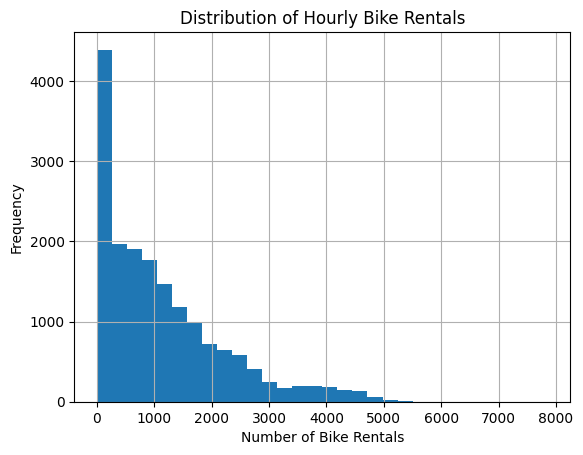

In [73]:
ax = df["cnt"].hist(bins=30)

ax.set_title("Distribution of Hourly Bike Rentals")
ax.set_xlabel("Number of Bike Rentals")
ax.set_ylabel("Frequency")


## 4. Hourly Rental Patterns

In [74]:
df["hour"] = df["timestamp"].dt.hour
df[["timestamp", "hour"]].head()


,timestamp,hour
0,2015-01-04 00:00:00,0
1,2015-01-04 01:00:00,1
2,2015-01-04 02:00:00,2
3,2015-01-04 03:00:00,3
4,2015-01-04 04:00:00,4


In [75]:
hourly_avg = df.groupby("hour")["cnt"].mean()
hourly_avg


hour
0      290.609116
1      200.631215
2      136.303745
3       94.245492
4       73.313454
5      110.707351
6      466.626722
7     1468.745179
8     2882.823204
9     1653.019257
10    1064.660690
11    1151.218707
12    1433.717421
13    1505.739011
14    1472.004121
15    1564.621399
16    1869.801370
17    2829.585165
18    2629.043956
19    1651.510316
20    1059.781293
21     741.249311
22     592.409655
23     439.652355
Name: cnt, dtype: float64

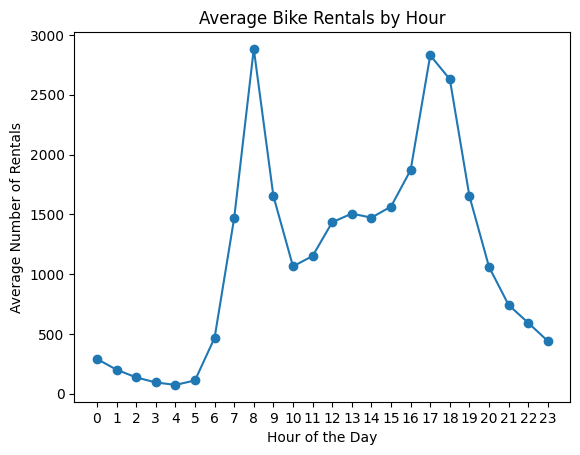

In [76]:

ax = hourly_avg.plot(kind="line", marker="o")
ax.set_title("Average Bike Rentals by Hour")
ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Average Number of Rentals")
ax.set_xticks(range(24));


## 5. Weekday vs Weekend Analysis

In [77]:
weekend_comparison = df.groupby(["is_weekend", "hour"])["cnt"].mean()

weekend_comparison.head(10)


is_weekend  hour
0.0         0        215.366795
            1        128.001931
            2         81.007737
            3         53.250000
            4         52.248062
            5        116.052326
            6        604.655106
            7       1969.518304
            8       3863.922780
            9       1997.605769
Name: cnt, dtype: float64

In [78]:
weekend_comparison = weekend_comparison.unstack(level=0)
weekend_comparison.head()

is_weekend,0.0,1.0
hour,,
0,215.366795,479.810680
1,128.001931,383.262136
2,81.007737,276.441176
3,53.250000,197.434146
4,52.248062,126.336585


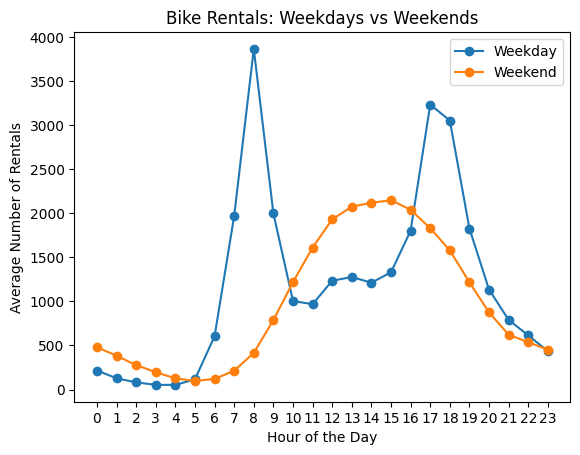

In [79]:
ax = weekend_comparison.plot(kind="line", marker="o")

ax.set_title("Bike Rentals: Weekdays vs Weekends")
ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Average Number of Rentals")
ax.set_xticks(range(24))
ax.legend(["Weekday", "Weekend"]);



### Weekday vs Weekend Bike Rental Patterns


The analysis reveals clear differences in bike rental patterns between weekdays and weekends.

On weekdays, rental demand peaks at around 8 AM and again between 5 PM and 6 PM. These peaks may be associated with commuting hours.

On weekends, demand increases later in the morning and remains relatively high throughout the afternoon, particularly between 12 PM and 4 PM.

These findings suggest that bike-sharing usage follows different patterns on weekdays and weekends, potentially reflecting commuting and leisure activities.

## 6. Temperature Analysis

Text(0, 0.5, 'Number of Bike Rentals')

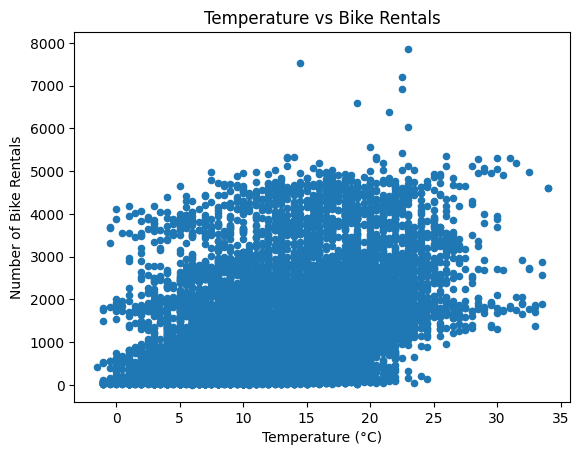

In [80]:
ax = df.plot.scatter(x="t1", y="cnt")

ax.set_title("Temperature vs Bike Rentals")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Number of Bike Rentals")


In [81]:
df["temp_group"] = (df["t1"] // 5) * 5

df[["t1", "temp_group"]].head(10)


,t1,temp_group
0,3.0,0.0
1,3.0,0.0
2,2.5,0.0
3,2.0,0.0
4,2.0,0.0
5,2.0,0.0
6,1.0,0.0
7,1.0,0.0
8,1.5,0.0
9,2.0,0.0


In [82]:
temp_avg = df.groupby("temp_group")["cnt"].mean()
temp_avg


temp_group
-5.0      554.025000
 0.0      622.633384
 5.0      822.611821
 10.0    1008.113016
 15.0    1349.726082
 20.0    2147.354922
 25.0    2809.427928
 30.0    2802.684211
Name: cnt, dtype: float64

In [83]:
df.groupby("temp_group")["cnt"].agg(["count", "mean"]).round(1)


,count,mean
temp_group,,
-5.0,40,554.0
0.0,1312,622.6
5.0,4382,822.6
10.0,5601,1008.1
15.0,4275,1349.7
20.0,1544,2147.4
25.0,222,2809.4
30.0,38,2802.7


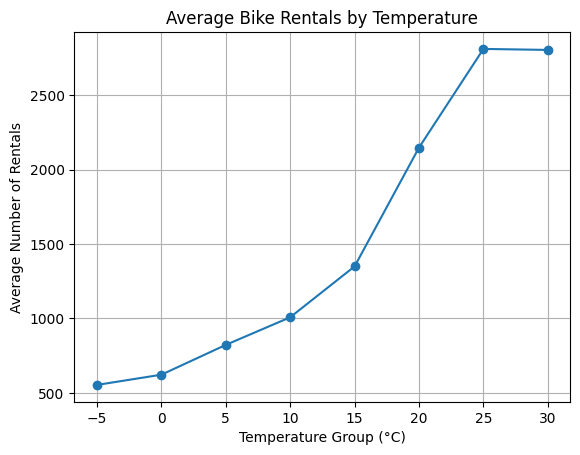

In [84]:
ax = temp_avg.plot(kind="line", marker="o")

ax.set_title("Average Bike Rentals by Temperature")
ax.set_xlabel("Temperature Group (°C)")
ax.set_ylabel("Average Number of Rentals")
ax.grid(True)


### Temperature and Bike Rental Demand

The analysis shows that average bike rental demand generally increases as temperature rises.

The highest average demand was observed in the 25–30°C temperature group, with approximately 2,809 rentals per hour.

Although the average decreases slightly in the 30–35°C group, this difference is very small. Additionally, this group contains only 38 observations, making the result less reliable.

Therefore, the data suggests a positive relationship between temperature and bike rental demand, but there is insufficient evidence to conclude that demand decreases at higher temperatures.

## 7. Weather Conditions and Rainfall 

In [85]:
df["weather_code"].value_counts().sort_index()


weather_code
1.0     6150
2.0     4034
3.0     3551
4.0     1464
7.0     2141
10.0      14
26.0      60
Name: count, dtype: int64

In [86]:
weather_stats = df.groupby("weather_code")["cnt"].agg(["count", "mean"]).round(1)

weather_stats


,count,mean
weather_code,,
1.0,6150,1162.1
2.0,4034,1496.2
3.0,3551,1195.1
4.0,1464,635.2
7.0,2141,713.0
10.0,14,583.4
26.0,60,250.8


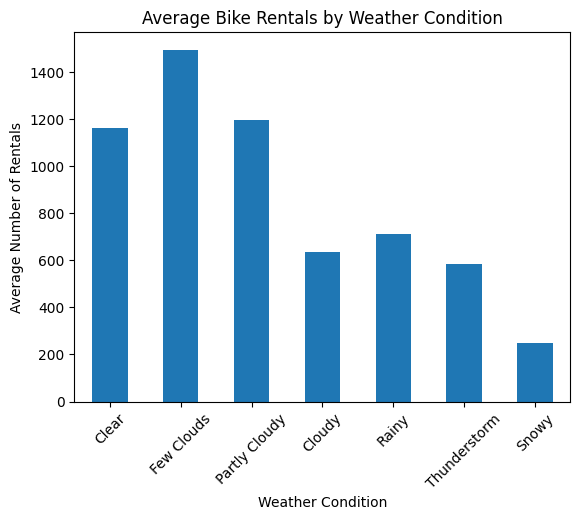

In [87]:
ax = weather_stats["mean"].plot(kind="bar")

ax.set_title("Average Bike Rentals by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Number of Rentals")


ax.set_xticklabels(
    ["Clear", "Few Clouds", "Partly Cloudy", "Cloudy",
     "Rainy", "Thunderstorm", "Snowy"],
    rotation=45
);




### Weather Conditions and Bike Rental Demand

The analysis shows that bike rental demand varies across different weather conditions.

The highest average number of rentals was observed during slightly cloudy weather, with approximately 1,496 rentals per hour.

Rainy conditions were associated with lower average demand (713 rentals per hour) compared with clear weather (1,162 rentals per hour).

Snowy conditions had the lowest average demand, although the relatively small number of observations (60) should be considered when interpreting this result.

Overall, the findings suggest an association between weather conditions and bike rental demand. However, other factors such as temperature, time of day and season may also influence these patterns.

## 8. Rainfall Analysis: Controlling for Temperature

In [88]:
df["is_rainy"] = df["weather_code"].isin([7, 10])

df[["weather_code", "is_rainy"]].head(10)


,weather_code,is_rainy
0,3.0,False
1,1.0,False
2,1.0,False
3,1.0,False
4,1.0,False
5,1.0,False
6,4.0,False
7,4.0,False
8,4.0,False
9,3.0,False


In [89]:
rain_comparison = df.groupby(["temp_group", "is_rainy"])["cnt"].agg(["count", "mean"])

rain_comparison.round(1)


count    mean
temp_group is_rainy               
-5.0       False        40   554.0
 0.0       False      1242   638.8
           True         70   335.9
 5.0       False      3757   866.1
           True        625   560.9
 10.0      False      4762  1066.5
           True        839   677.0
 15.0      False      3716  1419.9
           True        559   883.2
 20.0      False      1482  2170.5
           True         62  1593.6
 25.0      False       222  2809.4
 30.0      False        38  2802.7

In [90]:
rain_means = rain_comparison["mean"].unstack("is_rainy")

rain_means.round(1)


is_rainy,False,True
temp_group,,
-5.0,554.0,NaN
0.0,638.8,335.9
5.0,866.1,560.9
10.0,1066.5,677.0
15.0,1419.9,883.2
20.0,2170.5,1593.6
25.0,2809.4,NaN
30.0,2802.7,NaN


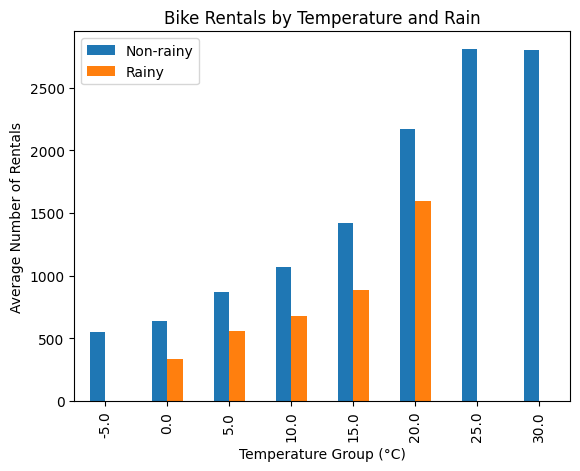

In [91]:
ax = rain_means.plot(kind="bar")

ax.set_title("Bike Rentals by Temperature and Rain")
ax.set_xlabel("Temperature Group (°C)")
ax.set_ylabel("Average Number of Rentals")
ax.legend(["Non-rainy", "Rainy"]);


### Rainfall and Bike Rental Demand: Controlling for Temperature

To investigate the relationship between rainfall and bike rental demand, observations were grouped into 5°C temperature intervals and classified as rainy or non-rainy.

Across all temperature groups containing both conditions, average bike rentals were lower during rainy hours.

For example, in the 10–15°C group, average hourly rentals were approximately 1,067 in non-rainy conditions compared with 677 in rainy conditions.

These findings suggest a negative association between rainfall and bike rental demand, even when comparing similar temperatures.

However, the analysis does not establish causation, as other factors such as time of day, season and day of the week may also influence demand.

## 9. Rainfall Analysis: Controlling for Time of Day

In [92]:
hourly_rain = df.groupby(["hour", "is_rainy"])["cnt"].mean()

hourly_rain = hourly_rain.unstack("is_rainy")

hourly_rain.head(10)


is_rainy,False,True
hour,,
0,306.156300,190.113402
1,212.831731,124.500000
2,142.584541,97.300000
3,97.782400,71.218750
4,75.569579,59.776699
5,113.724800,91.062500
6,484.239130,328.304878
7,1527.713190,949.189189
8,2958.861027,2070.935484


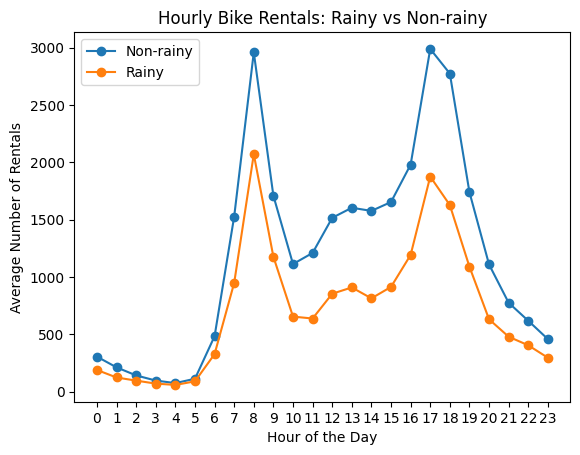

In [93]:

ax = hourly_rain.plot(kind="line", marker="o")

ax.set_title("Hourly Bike Rentals: Rainy vs Non-rainy")
ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Average Number of Rentals")
ax.set_xticks(range(24))
ax.legend(["Non-rainy", "Rainy"]);


### Hourly Bike Rental Patterns Under Rainy and Non-Rainy Conditions

The analysis shows that hourly bike rental patterns are broadly similar under rainy and non-rainy conditions.

Both groups display clear peaks at approximately 8 AM and 5 PM, suggesting that commuting patterns may remain important regardless of weather conditions.

However, average rental demand is consistently lower during rainy hours. For example, at 8 AM, average rentals decrease from approximately 2,959 in non-rainy conditions to 2,071 in rainy conditions.

These findings suggest that rainfall is associated with reduced bike rental demand, while the overall daily usage pattern remains relatively similar.

Further analysis would be needed to account for additional factors such as temperature, season and weekday differences.


## 10. Key Findings and Limitations


### Key Findings

**1. Hourly Rental Patterns**

Bike rentals are highest at around 8 AM and 5 PM. This could be because many people use bikes to travel to and from work or university. After the evening peak, the number of rentals gradually decreases.

**2. Weekday vs Weekend Patterns**

There is a clear difference between weekday and weekend rental patterns. During weekdays, the busiest hours are in the morning and late afternoon. However, on weekends, people tend to rent bikes later in the day, especially in the afternoon. This may be because bikes are used more for leisure activities rather than commuting.

**3. Temperature and Bike Rentals**

The results show that bike rentals generally increase as the temperature rises. The highest average was recorded between 25°C and 30°C. Although there was a slight decrease above 30°C, there were not enough observations to say that very hot weather reduces bike rentals.

**4. Weather Conditions and Rainfall**

Bike rentals were generally lower during rainy weather compared with clear weather. This difference was also seen when comparing rainy and non-rainy hours within similar temperature ranges.

However, the busiest hours were still around 8 AM and 5 PM in both weather conditions. This suggests that rain may reduce the number of rentals without completely changing the daily pattern.

### Limitations

There are some limitations to this analysis.

- Some temperature and weather groups had very few observations, so their averages may not be as reliable.
- Other factors, such as the season, time of day and whether it was a weekday or weekend, could also affect the results.
- Although some factors were compared separately, the analysis does not prove that weather directly causes changes in bike rentals.

### Conclusion

Overall, the results suggest that bike rentals in London are related to the time of day, temperature and weather conditions. The weekday and weekend patterns were also different.

The analysis helped me understand how these factors may be connected to bike rental demand. In future work, I could explore these relationships in more detail and use statistical methods to investigate them further.